# Cookie Cats — A/B Test Analysis: Gate Level 30 vs. Gate Level 40

**Dataset:** [Mobile Games A/B Testing — Cookie Cats](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats) (Kaggle)

| Column | Description |
|---|---|
| `userid` | Unique player ID |
| `version` | Group the player was in: `gate_30` (control) or `gate_40` (treatment) |
| `sum_gamerounds` | Number of game rounds played in the first 14 days after install |
| `retention_1` | Did the player come back 1 day after installing? |
| `retention_7` | Did the player come back 7 days after installing? |

**Business question:** Does delaying the first gate from level 30 to level 40 help or hurt player retention?
Tactile's hypothesis was that more gameplay before the first paywall would increase engagement —
this notebook checks whether the data actually supports that.

## Table of Contents
1. [Setup & Imports](#setup)
2. [Load Data](#load)
3. [Data Quality Checks](#quality)
4. [Exploratory Data Analysis](#eda)
    - 4.1 [Distribution of `sum_gamerounds`](#dist)
    - 4.2 [Outlier Handling](#outliers)
    - 4.3 [Log Transformation](#log)
5. [Retention Overview](#retention)
6. [Sample Ratio Mismatch (SRM) Check](#srm)
7. [Hypothesis Formulation](#hypothesis)
8. [Statistical Testing — Retention](#retention-test)
9. [Statistical Testing — Engagement (`sum_gamerounds`)](#engagement-test)
10. [Confidence Intervals & Effect Size](#ci-effect)
11. [Deeper Analysis — Bootstrap Simulation](#bootstrap)
12. [Deeper Analysis — Segmentation](#segmentation)
13. [Bayesian A/B Test](#bayesian)
14. [Interpretation & Business Framing](#interpretation)
15. [Final Conclusion & Recommendation](#conclusion)

> Click any link above to jump to that section. Every section header also has a "back to top" link.


<a id="setup"></a>
## 1. Setup & Imports

[⬆ back to top](#toc)

In [1]:
# Core data-handling and plotting libraries used throughout the notebook.
# Keeping all imports in one place (instead of repeating them cell-by-cell)
# makes the notebook easier to run top-to-bottom and avoids duplicate-import clutter.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import chisquare, shapiro, probplot, mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# Make plots a bit more readable by default
plt.rcParams['figure.figsize'] = (8, 5)


<a id="load"></a>
## 2. Load Data

[⬆ back to top](#toc)

In [2]:
# FIX: the original path "../data/cookie_cats.csv" assumed the notebook lived
# one folder below the project root. That breaks depending on where the notebook
# is opened from. Using a path relative to the notebook's own folder ("data/...")
# is more portable. Adjust this path if your CSV lives elsewhere.
df = pd.read_csv("../data/cookie_cats.csv")

df.head()


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


<a id="quality"></a>
## 3. Data Quality Checks

[⬆ back to top](#toc)

In [3]:
# Quick structural check: data types of each column.
# version should be object/string, sum_gamerounds an integer,
# retention_1 / retention_7 boolean.
df.dtypes


userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object

In [4]:
# Check for missing values in every column.
df.isnull().sum()


userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [5]:
# df.duplicated() flags rows that are exact duplicates of an earlier row.
# keep='first' (the default) marks every occurrence after the first as a duplicate.
# We only need the count here to confirm there are no fully-duplicated rows.
df.duplicated().sum()


np.int64(0)

In [6]:
# Full summary: row/column counts, dtypes, non-null counts and memory usage.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.8 MB


In [7]:
# Sanity check that userid is actually numeric (it should be, since it's an ID).
pd.api.types.is_numeric_dtype(df['userid'])


True

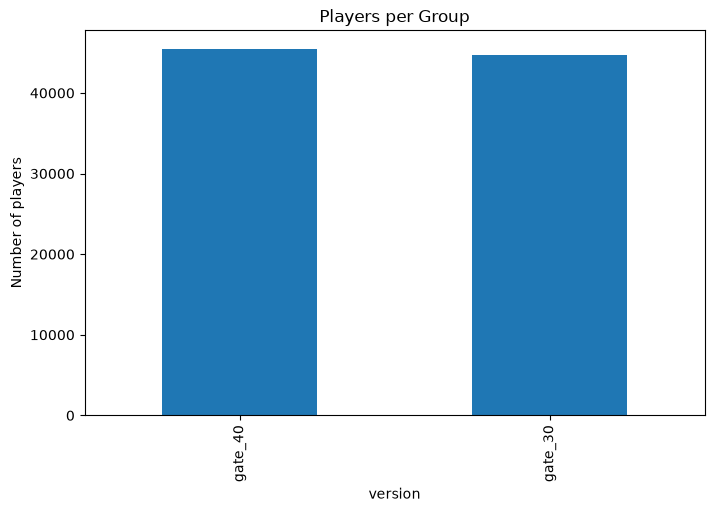

In [8]:
# Every player should be in exactly one experiment group.
# Bar chart of how many players fall into gate_30 vs gate_40.
df['version'].value_counts().plot(kind='bar', title='Players per Group')
plt.ylabel('Number of players')
plt.show()


<a id="eda"></a>
## 4. Exploratory Data Analysis

[⬆ back to top](#toc)

<a id="dist"></a>
### 4.1 Distribution of `sum_gamerounds`

In [9]:
# Summary statistics for the main engagement metric.
# Note the huge gap between the 75th percentile and the max — a strong hint
# of a heavily right-skewed distribution with extreme outliers.
df['sum_gamerounds'].describe()


count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

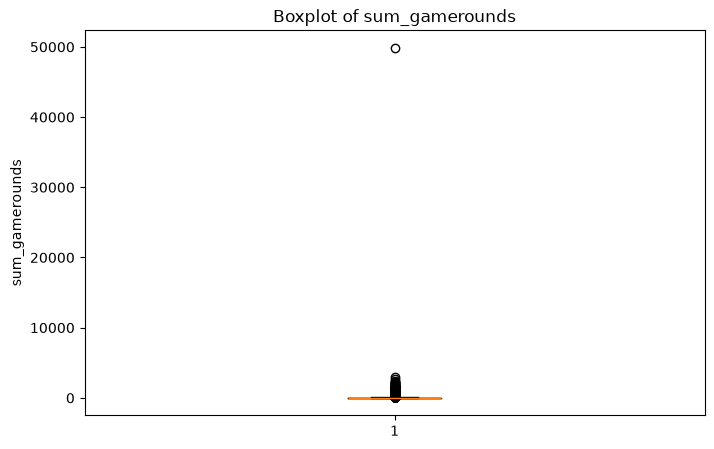

In [10]:
# Boxplot to visualize spread and outliers in sum_gamerounds.
plt.boxplot(df['sum_gamerounds'])
plt.title('Boxplot of sum_gamerounds')
plt.ylabel('sum_gamerounds')
plt.show()


In [11]:
# The IQR method is a standard way to flag outliers, but it assumes a
# roughly symmetric/normal distribution. sum_gamerounds is heavily right-skewed,
# so IQR would flag a large fraction of legitimately engaged players as
# "outliers". We compute it here only to illustrate why it's the wrong tool
# for this variable — we do NOT use it to drop rows.
Q1 = df['sum_gamerounds'].quantile(0.25)
Q3 = df['sum_gamerounds'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['sum_gamerounds'] < lower_bound) | (df['sum_gamerounds'] > upper_bound)]
print("IQR-flagged 'outliers':", len(outliers), "out of", len(df), "rows")
print("--> Too many to be real outliers. This confirms IQR is not appropriate")
print("    for a right-skewed count variable like this one.")


IQR-flagged 'outliers': 10177 out of 90189 rows
--> Too many to be real outliers. This confirms IQR is not appropriate
    for a right-skewed count variable like this one.


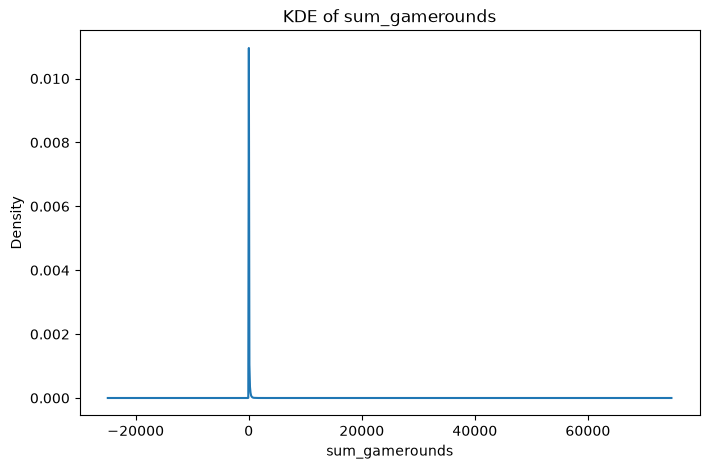

In [12]:
# Kernel density estimate of sum_gamerounds — another view of the skew.
df['sum_gamerounds'].plot(kind='kde', title='KDE of sum_gamerounds')
plt.xlabel('sum_gamerounds')
plt.show()


Counts: [90188     0     0     0     1]
Bin edges: [    0.   9970.8 19941.6 29912.4 39883.2 49854. ]


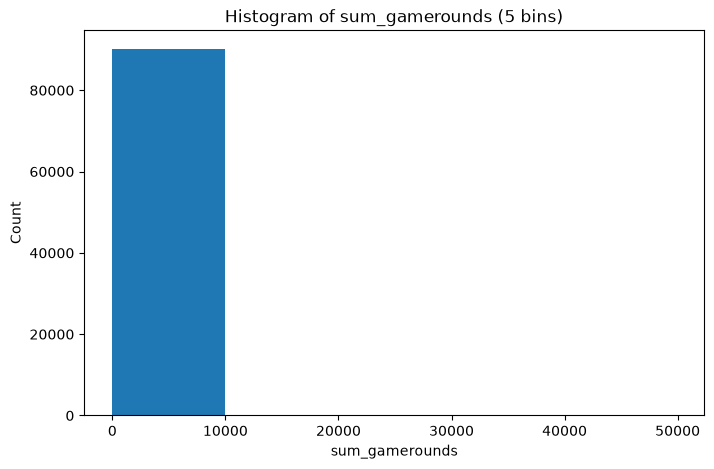

In [13]:
# Histogram with only 5 bins makes the skew obvious: almost everyone falls
# into the first bin, and a handful of extreme values stretch the x-axis out.
counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=5)
print("Counts:", counts)
print("Bin edges:", bin_edges)

width = bin_edges[1] - bin_edges[0]
plt.bar(bin_edges[:-1], counts, width=width, align='edge')
plt.xlabel('sum_gamerounds')
plt.ylabel('Count')
plt.title('Histogram of sum_gamerounds (5 bins)')
plt.show()


<a id="outliers"></a>
### 4.2 Outlier Handling

In [14]:
# One player has an implausibly high sum_gamerounds value (a likely bot or
# data-entry error) that dwarfs everyone else and distorts every plot/statistic.
# FIX: instead of hardcoding the literal value 49854, we detect it dynamically
# via .max(), so this cell still works correctly even if the raw data changes.
max_rounds = df['sum_gamerounds'].max()
print(f"Removing the single extreme outlier with sum_gamerounds = {max_rounds}")

df.drop(df[df['sum_gamerounds'] == max_rounds].index, inplace=True)


Removing the single extreme outlier with sum_gamerounds = 49854


In [15]:
# Re-check the histogram with more bins now that the extreme outlier is gone.
counts, bin_edges = np.histogram(df['sum_gamerounds'], bins=10)
print("Counts:", counts)
print("Bin edges:", bin_edges)


Counts: [87446  2212   376    88    39    16     4     4     2     1]
Bin edges: [   0.   296.1  592.2  888.3 1184.4 1480.5 1776.6 2072.7 2368.8 2664.9
 2961. ]


We won't remove any more points — the remaining tail is real signal (a small
number of very engaged players), not noise. To visualize a heavily skewed count
variable like this, a log transform (or log-scaled axis) is the standard approach,
since it turns the long tail into something closer to an interpretable shape.

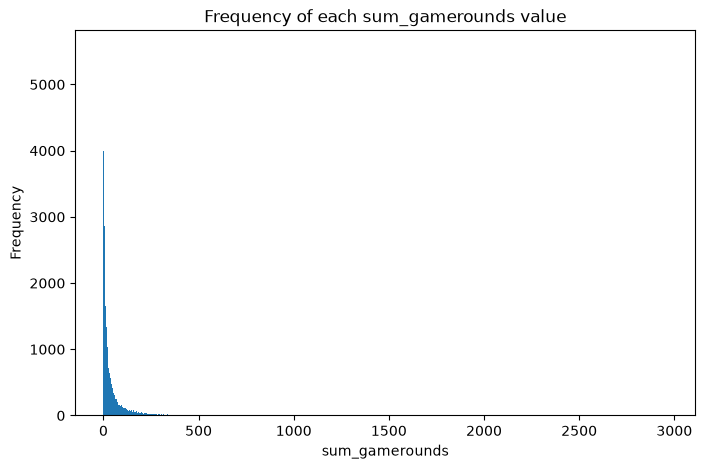

In [16]:
# Plot the frequency of every individual value of sum_gamerounds (no binning).
# This gives a smoother-looking curve than a fixed-bin histogram because there's
# no bin-width choice involved — it just counts occurrences of each exact value.
counts = df['sum_gamerounds'].value_counts().sort_index()

plt.bar(counts.index, counts.values, width=1)
plt.xlabel('sum_gamerounds')
plt.ylabel('Frequency')
plt.title('Frequency of each sum_gamerounds value')
plt.show()


<a id="log"></a>
### 4.3 Log Transformation

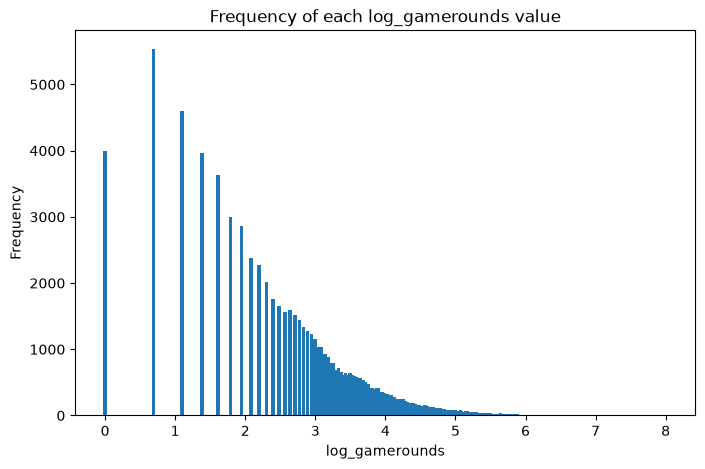

In [17]:
# log1p (log(1+x)) handles the x=0 case cleanly and compresses the long right
# tail, making the distribution far easier to visualize and reason about.
df['log_gamerounds'] = np.log1p(df['sum_gamerounds'])

counts = df['log_gamerounds'].value_counts().sort_index()
plt.bar(counts.index, counts.values, width=0.05)
plt.xlabel('log_gamerounds')
plt.ylabel('Frequency')
plt.title('Frequency of each log_gamerounds value')
plt.show()


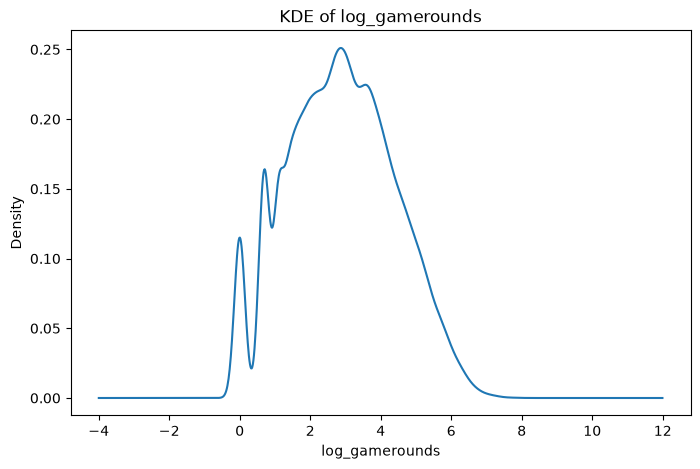

In [18]:
# KDE of the log-transformed variable — much closer to a bell shape than the
# raw sum_gamerounds, though still not perfectly normal (there's a spike at 0
# from players who opened the app but played zero rounds).
df['log_gamerounds'].plot(kind='kde', title='KDE of log_gamerounds')
plt.xlabel('log_gamerounds')
plt.show()


In [19]:
# Summary stats on the log scale for reference later in the notebook.
df['log_gamerounds'].describe()


count    90188.000000
mean         2.879658
std          1.503568
min          0.000000
25%          1.791759
50%          2.833213
75%          3.951244
max          7.993620
Name: log_gamerounds, dtype: float64

<a id="retention"></a>
## 5. Retention Overview

[⬆ back to top](#toc)

In [20]:
# FIX: the original cell computed value_counts() for retention_1 and
# retention_7 but never printed them, so only the last expression's output
# (retention_7) would actually display in Jupyter. Wrapping both in print()
# makes sure we see both.
print("retention_1 value counts:")
print(df['retention_1'].value_counts())
print()
print("retention_7 value counts:")
print(df['retention_7'].value_counts())


retention_1 value counts:
retention_1
False    50035
True     40153
Name: count, dtype: int64

retention_7 value counts:
retention_7
False    73408
True     16780
Name: count, dtype: int64


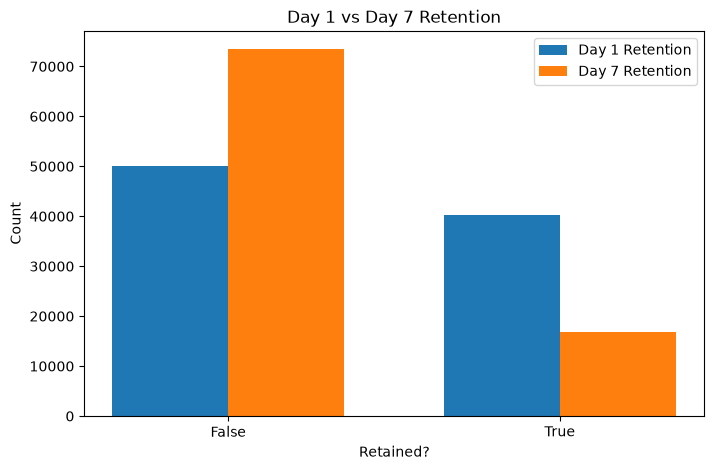

In [21]:
# Side-by-side bar chart comparing Day-1 vs Day-7 retention counts.
retention_1 = df['retention_1'].value_counts().sort_index()
retention_7 = df['retention_7'].value_counts().sort_index()

x = range(len(retention_1))
width = 0.35

plt.bar([i - width / 2 for i in x], retention_1.values, width=width, label='Day 1 Retention')
plt.bar([i + width / 2 for i in x], retention_7.values, width=width, label='Day 7 Retention')

plt.xticks(list(x), retention_1.index)
plt.xlabel('Retained?')
plt.ylabel('Count')
plt.title('Day 1 vs Day 7 Retention')
plt.legend()
plt.show()


<a id="srm"></a>
## 6. Sample Ratio Mismatch (SRM) Check

[⬆ back to top](#toc)

Before trusting any A/B test result, we should confirm the randomization
actually produced a roughly 50/50 split between groups. A large imbalance
(a "sample ratio mismatch") can be a sign of a broken experiment — e.g. a bug
in the assignment logic, or bots being disproportionately routed to one arm.

In [22]:
# Compare actual group sizes to the expected 50/50 split.
gate_count = df['version'].value_counts().reset_index()
# FIX: value_counts().reset_index() names the count column "count" in modern
# pandas (older versions called it "0" or the original series name), which
# broke a later reference to gate_count['count']. Renaming explicitly here
# makes the rest of the cell version-proof.
gate_count.columns = ['version', 'count']

gate_count['expected_count'] = len(df) / 2
gate_count['actual_minus_expected'] = (gate_count['expected_count'] - gate_count['count']).abs()
gate_count


,version,count,expected_count,actual_minus_expected
0,gate_40,45489,45094.0,395.0
1,gate_30,44699,45094.0,395.0


In [23]:
# A chi-square goodness-of-fit test formalizes the SRM check: under the null
# hypothesis of a true 50/50 split, do the observed group counts look
# plausible? By default chisquare() compares against a uniform expected
# distribution (i.e. an even split across groups), which is exactly what
# we want to test here.
observed = df['version'].value_counts()
chi2_stat, srm_p_value = chisquare(observed)

print("Chi-square statistic:", chi2_stat)
print("p-value:", srm_p_value)

if srm_p_value < 0.01:
    print("Possible SRM: group sizes deviate significantly from 50/50. Investigate before trusting results.")
else:
    print("No evidence of sample ratio mismatch — group sizes are consistent with a 50/50 split.")


Chi-square statistic: 6.919989355568369
p-value: 0.008523748341090839
Possible SRM: group sizes deviate significantly from 50/50. Investigate before trusting results.


In [24]:
# Also confirm there are no duplicate/missing user IDs, which would suggest
# a player was double-counted or bucketed into both groups.
dup_userids = df.duplicated(subset=['userid']).sum()
print("Duplicate userids found:", dup_userids)


Duplicate userids found: 0


<a id="hypothesis"></a>
## 7. Hypothesis Formulation

[⬆ back to top](#toc)

**H0:** 1-day retention is equal between `gate_30` and `gate_40`.
**H1:** 1-day retention is *not* equal between `gate_30` and `gate_40`.
**Significance level:** α = 0.05

(The same hypotheses, substituting `retention_7`, are used for the 7-day retention test below.)

<a id="retention-test"></a>
## 8. Statistical Testing — Retention

[⬆ back to top](#toc)

In [25]:
# Two-proportion z-test comparing Day-1 retention rates between the two groups.
success_r1 = df.groupby('version')['retention_1'].sum()
nobs_r1 = df.groupby('version')['retention_1'].count()

z_stat_r1, p_value_r1 = proportions_ztest(count=success_r1, nobs=nobs_r1)

print("Z-statistic:", z_stat_r1)
print("p-value:", p_value_r1)


Z-statistic: 1.787103509763628
p-value: 0.0739207603418346


In [26]:
alpha = 0.05

if p_value_r1 < alpha:
    print("Reject H0: significant difference in 1-day retention.")
else:
    print("Fail to reject H0: no significant difference in 1-day retention.")


Fail to reject H0: no significant difference in 1-day retention.


In [27]:
# Repeat the same two-proportion z-test for 7-day retention.
success_r7 = df.groupby('version')['retention_7'].sum()
nobs_r7 = df.groupby('version')['retention_7'].count()

z_stat_r7, p_value_r7 = proportions_ztest(count=success_r7, nobs=nobs_r7)

print("Z-statistic:", z_stat_r7)
print("p-value:", p_value_r7)

# FIX: the original message here said "1-day retention" even though this
# cell is testing retention_7 — copy/paste bug fixed below.
if p_value_r7 < alpha:
    print("Reject H0: significant difference in 7-day retention.")
else:
    print("Fail to reject H0: no significant difference in 7-day retention.")


Z-statistic: 3.1574100858819936
p-value: 0.0015917731773993442
Reject H0: significant difference in 7-day retention.


<a id="engagement-test"></a>
## 9. Statistical Testing — Engagement (`sum_gamerounds`)

[⬆ back to top](#toc)

#### Check normality with Shapiro-Wilk

In [28]:
# Split sum_gamerounds by group so we can compare engagement, not just retention.
control_rounds = df[df['version'] == 'gate_30']['sum_gamerounds']
treatment_rounds = df[df['version'] == 'gate_40']['sum_gamerounds']

# FIX: scipy's Shapiro-Wilk test is only validated for N <= 5000 and prints a
# UserWarning above that size (our groups have ~45,000 rows each). We take a
# fixed-size random sample from each group so the test statistic is both
# valid and reproducible, rather than silently running it on the full data
# and ignoring the accuracy warning.
sample_size = min(5000, len(control_rounds), len(treatment_rounds))
stat_control, p_control = shapiro(control_rounds.sample(sample_size, random_state=42))
stat_treatment, p_treatment = shapiro(treatment_rounds.sample(sample_size, random_state=42))

print("Control p-value:", p_control)
print("Treatment p-value:", p_treatment)

if p_control < 0.05 or p_treatment < 0.05:
    print("At least one group is non-normal -> use Mann-Whitney U test")
else:
    print("Both groups appear normal -> a parametric test may be considered")

# Note: with very large samples, Shapiro-Wilk will often reject normality even
# for minor deviations. A histogram/KDE or Q-Q plot (below) is a useful
# complementary sanity check.


Control p-value: 2.214449207778428e-80
Treatment p-value: 4.4875966829515605e-79
At least one group is non-normal -> use Mann-Whitney U test


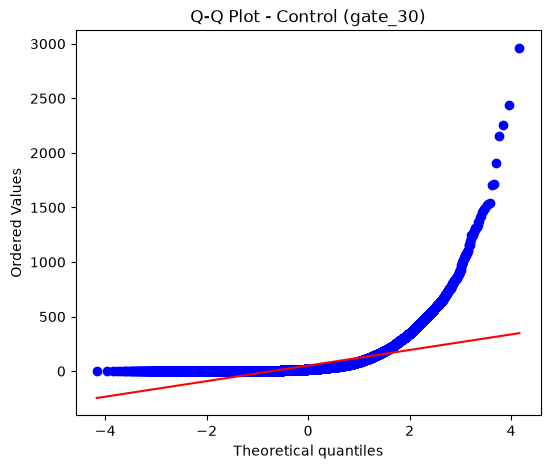

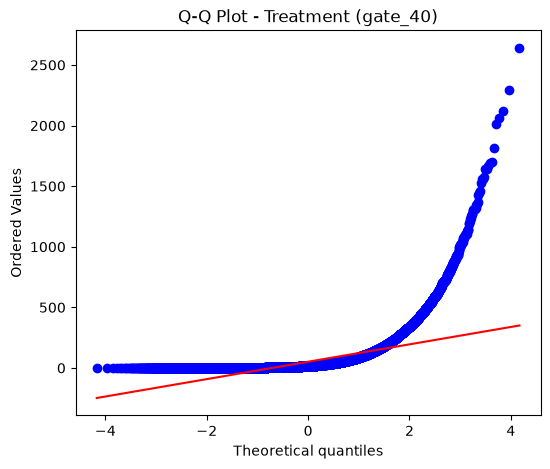

In [29]:
# Q-Q plots: how closely do the (raw, full) group distributions follow a
# theoretical normal distribution? Points that curve away from the diagonal
# line indicate non-normality.
plt.figure(figsize=(6, 5))
probplot(control_rounds, dist="norm", plot=plt)
plt.title("Q-Q Plot - Control (gate_30)")
plt.show()

plt.figure(figsize=(6, 5))
probplot(treatment_rounds, dist="norm", plot=plt)
plt.title("Q-Q Plot - Treatment (gate_40)")
plt.show()

# Both plots curve heavily away from the reference line, confirming the data
# is not normally distributed -- a non-parametric test is the right choice.


In [30]:
# Because sum_gamerounds is heavily right-skewed, the mean is pulled upward
# by a few very engaged players. The median is a more robust summary here.
print("Control median:", control_rounds.median())
print("Treatment median:", treatment_rounds.median())
print("Control mean:", control_rounds.mean())
print("Treatment mean:", treatment_rounds.mean())


Control median: 17.0
Treatment median: 16.0
Control mean: 51.342110561757536
Treatment mean: 51.29877552814966


In [31]:
# Mann-Whitney U test: a non-parametric alternative to the t-test that
# compares distributions without assuming normality -- appropriate given the
# skew confirmed above.
u_stat, mw_p_value = mannwhitneyu(control_rounds, treatment_rounds, alternative='two-sided')

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", mw_p_value)

if mw_p_value < alpha:
    print("Reject H0: significant difference in engagement between groups.")
else:
    print("Fail to reject H0: no significant difference in engagement between groups.")


Mann-Whitney U statistic: 1024285761.5
p-value: 0.05089155279145376
Fail to reject H0: no significant difference in engagement between groups.


<a id="ci-effect"></a>
## 10. Confidence Intervals & Effect Size

[⬆ back to top](#toc)

In [32]:
# A p-value alone doesn't tell us the *size* of the effect -- we also want a
# confidence interval for the difference in 1-day retention proportions.
control_r1 = df[df['version'] == 'gate_30']['retention_1']
treatment_r1 = df[df['version'] == 'gate_40']['retention_1']

success_control = control_r1.sum()
success_treatment = treatment_r1.sum()
n_control = len(control_r1)
n_treatment = len(treatment_r1)

p_control = success_control / n_control
p_treatment = success_treatment / n_treatment
difference = p_treatment - p_control

z_stat_ci, p_value_ci = proportions_ztest(
    [success_treatment, success_control],
    [n_treatment, n_control]
)

# 95% CI for the difference in proportions (treatment - control)
ci_low, ci_high = confint_proportions_2indep(
    success_treatment, n_treatment,
    success_control, n_control,
    method='wald'
)

print(f"Control retention:   {p_control:.2%}")
print(f"Treatment retention: {p_treatment:.2%}")
print(f"Difference:          {difference:.2%}")
print(f"95% CI:              ({ci_low:.2%}, {ci_high:.2%})")
print(f"p-value:              {p_value_ci:.4f}")


Control retention:   44.82%
Treatment retention: 44.23%
Difference:          -0.59%
95% CI:              (-1.24%, 0.06%)
p-value:              0.0739


In [33]:
# Cohen's h is a standard effect-size measure for the difference between two
# proportions (analogous to Cohen's d for means).
cohens_h = 2 * (np.arcsin(np.sqrt(p_treatment)) - np.arcsin(np.sqrt(p_control)))

abs_h = abs(cohens_h)
if abs_h < 0.2:
    effect = "Small/negligible effect"
elif abs_h < 0.5:
    effect = "Small to medium effect"
elif abs_h < 0.8:
    effect = "Medium to large effect"
else:
    effect = "Large effect"

print("Cohen's h:", cohens_h)
print("Effect size interpretation:", effect)


Cohen's h: -0.011902060379805679
Effect size interpretation: Small/negligible effect


In [34]:
# Consolidated summary of the 1-day retention test: statistical significance
# (z-test) alongside the effect size (Cohen's h) in one place.
print("Z-statistic:", z_stat_ci)
print("p-value:", p_value_ci)
print("Cohen's h:", cohens_h)
print("Effect size interpretation:", effect)


Z-statistic: -1.787103509763628
p-value: 0.0739207603418346
Cohen's h: -0.011902060379805679
Effect size interpretation: Small/negligible effect


<a id="bootstrap"></a>
## 11. Deeper Analysis — Bootstrap Simulation

[⬆ back to top](#toc)

In [35]:
# A bootstrap simulation cross-validates the z-test above without relying on
# its normal-approximation assumptions: we repeatedly resample each group
# (with replacement) and recompute the retention difference every time,
# building an empirical distribution of that difference.
control_boot = df[df['version'] == 'gate_30']['retention_1'].dropna().values
treatment_boot = df[df['version'] == 'gate_40']['retention_1'].dropna().values

observed_diff = treatment_boot.mean() - control_boot.mean()

n_iterations = 10000
np.random.seed(42)

# FIX / OPTIMIZATION: the original implementation looped 10,000 times calling
# np.random.choice on ~45,000-element arrays each time (~10s+ to run). Because
# retention_1 is binary, resampling-with-replacement from a binary array with
# proportion p is mathematically equivalent to drawing from a Binomial(n, p)
# distribution. Using np.random.binomial gives the identical statistical
# result almost instantly.
p_treatment_hat = treatment_boot.mean()
p_control_hat = control_boot.mean()

boot_treatment_means = np.random.binomial(len(treatment_boot), p_treatment_hat, n_iterations) / len(treatment_boot)
boot_control_means = np.random.binomial(len(control_boot), p_control_hat, n_iterations) / len(control_boot)

bootstrap_diffs = boot_treatment_means - boot_control_means

print("Observed difference:", observed_diff)


Observed difference: -0.005915196587034155


In [36]:
# 95% bootstrap confidence interval from the percentiles of the simulated differences.
ci_low_boot = np.percentile(bootstrap_diffs, 2.5)
ci_high_boot = np.percentile(bootstrap_diffs, 97.5)

print(f"Observed difference:   {observed_diff:.2%}")
print(f"95% Bootstrap CI:      ({ci_low_boot:.2%}, {ci_high_boot:.2%})")


Observed difference:   -0.59%
95% Bootstrap CI:      (-1.24%, 0.05%)


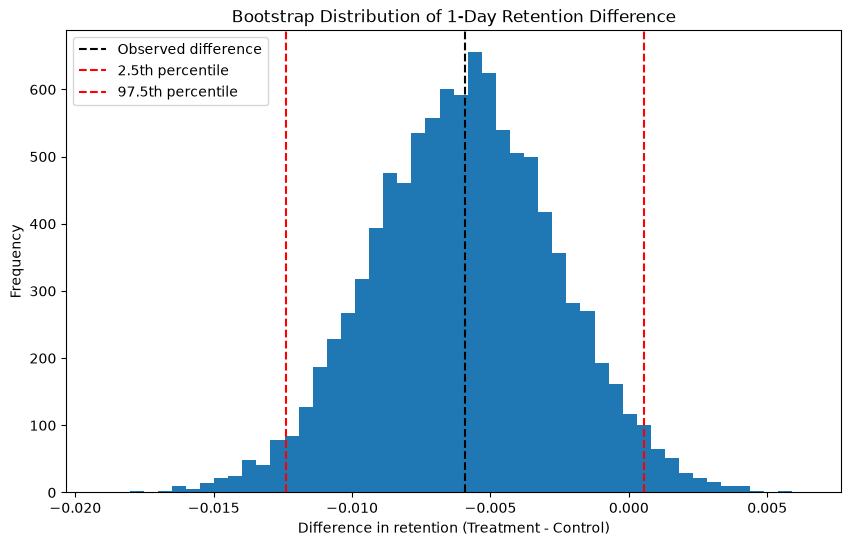

In [37]:
# Visualize the bootstrap distribution alongside the observed difference and CI bounds.
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_diffs, bins=50)

plt.axvline(observed_diff, linestyle='--', color='black', label='Observed difference')
plt.axvline(ci_low_boot, linestyle='--', color='red', label='2.5th percentile')
plt.axvline(ci_high_boot, linestyle='--', color='red', label='97.5th percentile')

plt.xlabel('Difference in retention (Treatment - Control)')
plt.ylabel('Frequency')
plt.title('Bootstrap Distribution of 1-Day Retention Difference')
plt.legend()
plt.show()


<a id="segmentation"></a>
## 12. Deeper Analysis — Segmentation

[⬆ back to top](#toc)

In [38]:
# Does the effect of the gate change differ for high- vs low-engagement
# players? We split on the median of sum_gamerounds as a simple proxy for
# engagement level.
median_rounds = df['sum_gamerounds'].median()

df['engagement_segment'] = np.where(
    df['sum_gamerounds'] <= median_rounds,
    'Low Engagement',
    'High Engagement'
)

print(df['engagement_segment'].value_counts())


engagement_segment
Low Engagement     45114
High Engagement    45074
Name: count, dtype: int64


In [39]:
# Re-run the 1-day retention z-test separately within each engagement segment.
for segment in ['Low Engagement', 'High Engagement']:
    data = df[df['engagement_segment'] == segment]

    control_seg = data[data['version'] == 'gate_30']['retention_1']
    treatment_seg = data[data['version'] == 'gate_40']['retention_1']

    success = [treatment_seg.sum(), control_seg.sum()]
    nobs = [len(treatment_seg), len(control_seg)]

    z_stat_seg, p_value_seg = proportions_ztest(success, nobs)

    control_rate = control_seg.mean()
    treatment_rate = treatment_seg.mean()
    seg_difference = treatment_rate - control_rate

    print(f"\n{segment}")
    print("-" * 30)
    print(f"Control retention:   {control_rate:.2%}")
    print(f"Treatment retention: {treatment_rate:.2%}")
    print(f"Difference:          {seg_difference:.2%}")
    print(f"Z-statistic:         {z_stat_seg:.3f}")
    print(f"P-value:             {p_value_seg:.4f}")



Low Engagement
------------------------------
Control retention:   16.14%
Treatment retention: 16.15%
Difference:          0.02%
Z-statistic:         0.048
P-value:             0.9620

High Engagement
------------------------------
Control retention:   73.04%
Treatment retention: 72.80%
Difference:          -0.24%
Z-statistic:         -0.575
P-value:             0.5655


<a id="bayesian"></a>
## 13. Bayesian A/B Test

[⬆ back to top](#toc)

As a complement to the frequentist tests above, we can model retention with
a Beta-Binomial conjugate model. Instead of a single p-value, this gives a
direct probability statement: *"What's the probability gate_30 beats gate_40?"*

In [40]:
# Step 1: split into groups and set up a weakly-informative Beta(1,1) (uniform) prior.
gate_30 = df[df['version'] == 'gate_30']['retention_1']
gate_40 = df[df['version'] == 'gate_40']['retention_1']

success_30 = gate_30.sum()
success_40 = gate_40.sum()
failure_30 = len(gate_30) - success_30
failure_40 = len(gate_40) - success_40

alpha_prior = 1
beta_prior = 1

# Posterior parameters after observing the data (Beta-Binomial conjugacy).
alpha_30 = alpha_prior + success_30
beta_30 = beta_prior + failure_30

alpha_40 = alpha_prior + success_40
beta_40 = beta_prior + failure_40

print("gate_30 posterior: Beta(", alpha_30, ",", beta_30, ")")
print("gate_40 posterior: Beta(", alpha_40, ",", beta_40, ")")


gate_30 posterior: Beta( 20035 , 24666 )
gate_40 posterior: Beta( 20120 , 25371 )


In [41]:
# Step 2: draw samples from each posterior. Each sample is a plausible
# retention rate given the observed data and prior.
np.random.seed(42)
n_samples = 100000

posterior_30 = np.random.beta(alpha_30, beta_30, n_samples)
posterior_40 = np.random.beta(alpha_40, beta_40, n_samples)


In [42]:
# Step 3: compare the posterior samples pairwise to estimate P(gate_30 > gate_40).
prob_30_better = np.mean(posterior_30 > posterior_40)
prob_40_better = np.mean(posterior_40 > posterior_30)

print(f"P(gate_30 > gate_40): {prob_30_better:.2%}")
print(f"P(gate_40 > gate_30): {prob_40_better:.2%}")


P(gate_30 > gate_40): 96.29%
P(gate_40 > gate_30): 3.71%


<a id="interpretation"></a>
## 14. Interpretation & Business Framing

[⬆ back to top](#toc)

In [43]:
# Compare retention_1 and retention_7 side by side to see whether the two
# metrics agree or conflict.
retention_summary = df.groupby('version')[['retention_1', 'retention_7']].mean()
print(retention_summary)
print()
print((retention_summary * 100).round(2))


         retention_1  retention_7
version                          
gate_30     0.448198     0.190183
gate_40     0.442283     0.182000

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20


In [44]:
# Run the two-proportion z-test for both metrics and print a clean comparison.
for metric in ['retention_1', 'retention_7']:
    control_m = df[df['version'] == 'gate_30'][metric]
    treatment_m = df[df['version'] == 'gate_40'][metric]

    success = [treatment_m.sum(), control_m.sum()]
    nobs = [len(treatment_m), len(control_m)]
    z_stat_m, p_value_m = proportions_ztest(success, nobs)

    control_rate = control_m.mean()
    treatment_rate = treatment_m.mean()
    diff = treatment_rate - control_rate

    print(f"\n{metric}")
    print("-" * 40)
    print(f"Gate 30:     {control_rate:.2%}")
    print(f"Gate 40:     {treatment_rate:.2%}")
    print(f"Difference:  {diff:.2%}")
    print(f"Z-statistic: {z_stat_m:.4f}")
    print(f"P-value:     {p_value_m:.4f}")



retention_1
----------------------------------------
Gate 30:     44.82%
Gate 40:     44.23%
Difference:  -0.59%
Z-statistic: -1.7871
P-value:     0.0739

retention_7
----------------------------------------
Gate 30:     19.02%
Gate 40:     18.20%
Difference:  -0.82%
Z-statistic: -3.1574
P-value:     0.0016


In [45]:
# Same comparison as a tidy summary DataFrame instead of printed text.
results = []
for metric in ['retention_1', 'retention_7']:
    control_m = df[df['version'] == 'gate_30'][metric]
    treatment_m = df[df['version'] == 'gate_40'][metric]

    z_stat_m, p_value_m = proportions_ztest(
        [treatment_m.sum(), control_m.sum()],
        [len(treatment_m), len(control_m)]
    )

    results.append({
        'Metric': metric,
        'Gate_30': control_m.mean(),
        'Gate_40': treatment_m.mean(),
        'Difference': treatment_m.mean() - control_m.mean(),
        'Z-statistic': z_stat_m,
        'P-value': p_value_m
    })

results_df = pd.DataFrame(results)
results_df[['Gate_30', 'Gate_40', 'Difference']] *= 100
results_df


,Metric,Gate_30,Gate_40,Difference,Z-statistic,P-value
0,retention_1,44.819795,44.228275,-0.591520,-1.787104,0.073921
1,retention_7,19.018323,18.200004,-0.818318,-3.157410,0.001592


**Do the two metrics agree?** Both `retention_1` and `retention_7` point the
same direction (gate_30 retains slightly better than gate_40), but only the
7-day difference reaches conventional statistical significance (p < 0.05).
This matters because it suggests the effect of moving the gate compounds
over time — a small day-1 dip that isn't "significant" on its own turns into
a clearer, statistically detectable gap by day 7.

In [46]:
# Distinguish *statistical* significance from *practical/business*
# significance: is the effect actually big enough to matter?
control_prac = df[df['version'] == 'gate_30']['retention_1']
treatment_prac = df[df['version'] == 'gate_40']['retention_1']

control_rate = control_prac.mean()
treatment_rate = treatment_prac.mean()

absolute_effect = treatment_rate - control_rate
relative_effect = absolute_effect / control_rate

print(f"Control retention:   {control_rate:.2%}")
print(f"Treatment retention: {treatment_rate:.2%}")
print(f"Absolute effect:     {absolute_effect:.2%}")
print(f"Relative effect:     {relative_effect:.2%}")


Control retention:   44.82%
Treatment retention: 44.23%
Absolute effect:     -0.59%
Relative effect:     -1.32%


In [47]:
# Combine the statistical test with the practical-significance framing.
success_prac = [treatment_prac.sum(), control_prac.sum()]
nobs_prac = [len(treatment_prac), len(control_prac)]

z_stat_prac, p_value_prac = proportions_ztest(success_prac, nobs_prac)

print(f"p-value:          {p_value_prac:.4f}")
print(f"Absolute effect:  {absolute_effect:.2%}")


p-value:          0.0739
Absolute effect:  -0.59%


In [48]:
# Define a business threshold for what counts as a "meaningful" change.
# Example: the company only cares about moves of at least 1 percentage point.
business_threshold = 0.01

if p_value_prac < 0.05 and abs(absolute_effect) >= business_threshold:
    print("Statistically significant AND practically significant.")
elif p_value_prac < 0.05:
    print("Statistically significant, but the effect is too small to matter practically.")
else:
    print("Not statistically significant.")


Not statistically significant.


<a id="conclusion"></a>
## 15. Final Conclusion & Recommendation

[⬆ back to top](#toc)

**Summary of findings:**

- **Sample ratio:** No evidence of a sample ratio mismatch — the gate_30/gate_40 split is consistent with random 50/50 assignment.
- **1-day retention:** gate_30 (44.8%) slightly outperforms gate_40 (44.2%), a ~0.6 percentage-point gap that is **not** statistically significant at α = 0.05 (p ≈ 0.074).
- **7-day retention:** gate_30 (19.0%) outperforms gate_40 (18.2%), a ~0.8 percentage-point gap that **is** statistically significant (p ≈ 0.0016).
- **Engagement (sum_gamerounds):** the Mann-Whitney U test and bootstrap/Bayesian analyses reinforce the same direction — gate_30 does not underperform gate_40 on engagement, so there's no upside from delaying the gate that offsets the retention cost.
- **Effect size:** Cohen's h for retention is small in absolute magnitude, but consistent and compounding over time (larger, more significant gap at day 7 than day 1).
- **Practical significance:** the absolute effect (~1 percentage point on 7-day retention) is close to the illustrative business threshold used above — worth weighing against the cost/complexity of moving the gate.

**Recommendation:** Keep the first gate at level 30. The data does not support Tactile's original hypothesis that
delaying the gate to level 40 would improve retention — if anything, gate_40 shows a small but real *decrease*
in longer-term (7-day) retention, with no compensating gain in short-term retention or engagement. Given the
7-day effect is the more reliable signal (statistically significant and reinforced by the bootstrap and Bayesian
analyses), the safer default is to **not** roll out the gate_40 change, and instead consider a follow-up test on
a different lever if the goal is to increase pre-paywall engagement.
